<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson7/Lesson7_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 7 — Covariance and PCA: Finding the Dominant Patterns in Population Activity

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 2 — Linear Algebra II\
**Lesson:** Lesson 7\
**Notebook type:** Teaching notebook

> *"Sixty neurons do not give you sixty independent signals. Usually they share a handful of patterns, and the covariance matrix knows which."*

---

### Many neurons, few patterns

A modern recording gives hundreds of neurons at once, so each moment is a point in a space with hundreds of dimensions (Lesson 1). Nobody can look at that space directly. But neurons in a circuit are not independent: they share inputs and drive one another, so their activity moves together. If most of the variation lies along a few directions, we can describe the population with a few numbers instead of hundreds.

**Principal component analysis (PCA)** finds those directions. It is built from three pieces you already have: centring a data matrix (Lesson 3), projecting onto a unit vector (Lesson 2), and the eigenvectors of a symmetric matrix (Lesson 6). This lesson assembles them, shows what PCA can and cannot tell you, and then applies it to 170 neurons in monkey motor cortex.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-6.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-6.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: sixty neurons, two hidden signals**

We simulate a population so that we know the truth. Sixty neurons are recorded for 30 s in 50 ms bins, giving a data matrix $\mathbf{X}$ of shape $(600, 60)$: **rows are time bins, columns are neurons, entries are firing rates in spikes/s** (the Lesson 3 convention). Every neuron's rate is its own baseline, plus its own mixture of **two hidden signals** $z_1(t)$ and $z_2(t)$ that the whole circuit shares, plus private noise:

$$x_{t,i} = b_i + w_{i1}\,z_1(t) + w_{i2}\,z_2(t) + \varepsilon_{t,i}.$$

Look at the data first, as a heatmap. Can you see two signals?

X_sim shape: (600, 60) (time bin, neuron), spikes/s


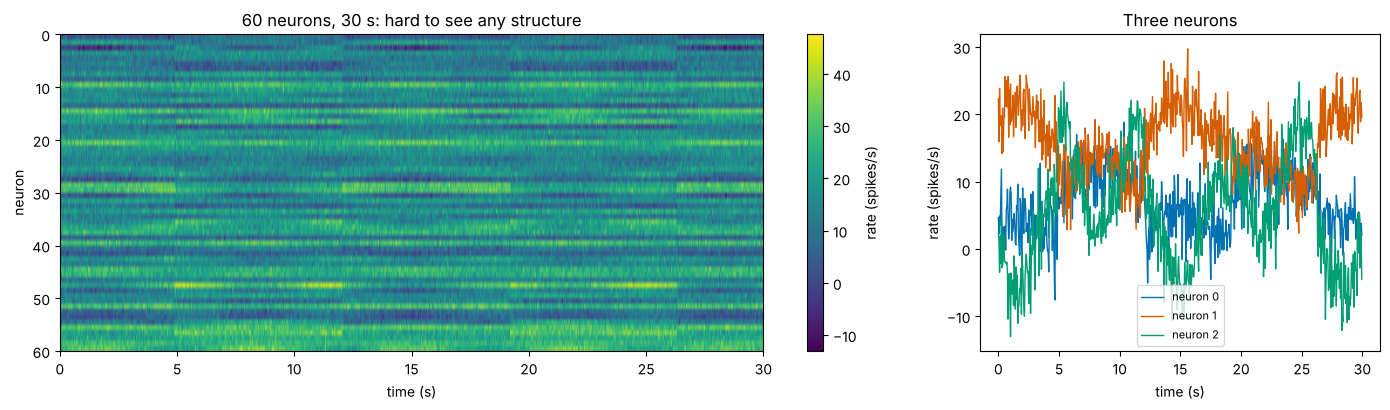

In [3]:
T_sim, N_sim, dt = 600, 60, 0.05
t_sim = np.arange(T_sim) * dt                                   # time in s, shape (600,)
z_true = np.column_stack([np.sin(2 * np.pi * 0.15 * t_sim),     # hidden signal 1: slow 0.15 Hz rhythm
                          np.sign(np.sin(2 * np.pi * 0.07 * t_sim + 1.0)) * 0.8])   # hidden signal 2: slow on/off switching
W_true = RNG.normal(0, 4, size=(N_sim, 2))                       # each neuron's mixing weights (spikes/s per unit signal), shape (60, 2)
baseline = RNG.uniform(5, 30, size=N_sim)                       # baseline rates (spikes/s), shape (60,)
noise_sd = 3.0
X_sim = baseline + z_true @ W_true.T + RNG.normal(0, noise_sd, size=(T_sim, N_sim))   # shape (600, 60): time bin x neuron, spikes/s
print("X_sim shape:", X_sim.shape, "(time bin, neuron), spikes/s")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
im = axes[0].imshow(X_sim.T, aspect='auto', cmap='viridis', extent=[0, T_sim * dt, N_sim, 0])
axes[0].set_xlabel('time (s)'); axes[0].set_ylabel('neuron'); axes[0].set_title('60 neurons, 30 s: hard to see any structure')
plt.colorbar(im, ax=axes[0], label='rate (spikes/s)')
for i, colour in zip([0, 1, 2], PALETTE):
    axes[1].plot(t_sim, X_sim[:, i], color=colour, lw=1, label=f'neuron {i}')
axes[1].set_xlabel('time (s)'); axes[1].set_ylabel('rate (spikes/s)'); axes[1].set_title('Three neurons'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Mostly noise and different baselines. Yet by construction the population lives, apart from noise, in a **two-dimensional** subspace of the 60-dimensional space. By the end of Part 4 PCA will have found that subspace and recovered both hidden signals from the data alone, without being told there were two.

# **Part 1: Mean-Centring and Variance**

For one neuron with rates $x_1, \dots, x_n$ over $n$ time bins:

- the **mean** $\bar x = \frac1n\sum_t x_t$ (spikes/s) is its baseline;
- the **deviations** $x_t - \bar x$ say how far each bin is from baseline;
- the **variance** $s^2 = \frac{1}{n-1}\sum_t (x_t - \bar x)^2$, in (spikes/s)$^2$, is the average squared deviation, and the **standard deviation** $s$ returns to spikes/s.

The divisor $n - 1$ instead of $n$ makes the sample variance an unbiased estimate (Lesson 17 explains why); for hundreds of bins the difference is negligible. NumPy's `np.var` divides by $n$ unless you pass `ddof=1`; `np.cov` divides by $n - 1$.

**Centring** subtracts each column's mean: $\mathbf{X}_c = \mathbf{X} - \mathbf{1}\bar{\mathbf{x}}^{\mathsf T}$ (in NumPy, `X - X.mean(axis=0)`, broadcasting as in Lesson 3). PCA studies **variation**, so it must start from centred data; otherwise the first "pattern" it finds is just the direction of the mean firing rates.

means (spikes/s): [ 7.02 15.81]
variances (spikes/s)^2, ddof=1: [20.25 25.99]   std (spikes/s): [4.5 5.1]
means after centring: [ 0. -0.]


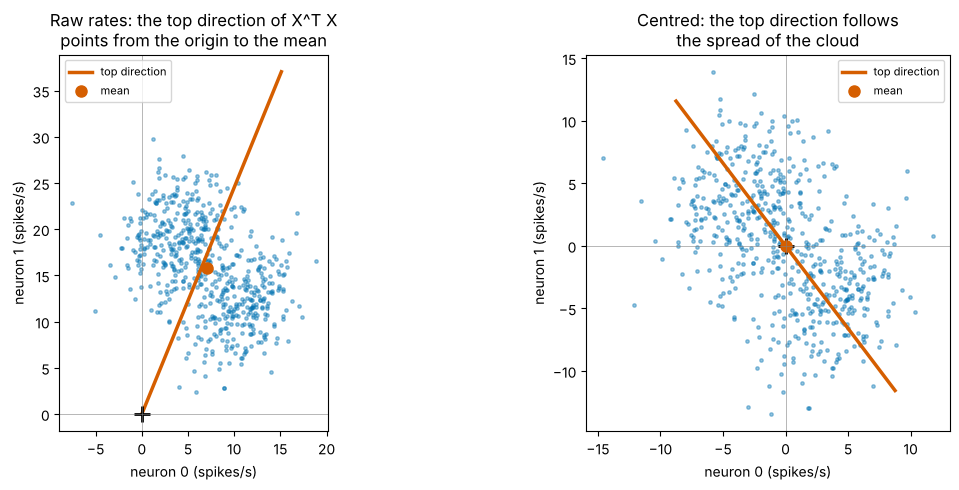

In [4]:
pair = X_sim[:, [0, 1]]                     # two neurons, shape (600, 2), spikes/s
means = pair.mean(axis=0)                   # shape (2,)
pair_c = pair - means                       # centred, shape (600, 2)
print("means (spikes/s):", np.round(means, 2))
print("variances (spikes/s)^2, ddof=1:", np.round(pair.var(axis=0, ddof=1), 2), "  std (spikes/s):", np.round(pair.std(axis=0, ddof=1), 2))
print("means after centring:", np.round(pair_c.mean(axis=0), 12))

# Without centring, the "top direction" of X^T X points at the mean, not along the cloud.
M_raw = pair.T @ pair
top_raw = np.linalg.eigh(M_raw)[1][:, -1]
top_c = np.linalg.eigh(pair_c.T @ pair_c)[1][:, -1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title, v in [(axes[0], pair, 'Raw rates: the top direction of X^T X\npoints from the origin to the mean', top_raw),
                           (axes[1], pair_c, 'Centred: the top direction follows\nthe spread of the cloud', top_c)]:
    ax.scatter(data[:, 0], data[:, 1], s=6, alpha=0.4, color=PALETTE[0])
    c0 = data.mean(axis=0)
    L = 2.5 * np.sqrt(np.max(np.linalg.eigvalsh(np.cov(data, rowvar=False))))
    if data is pair:
        ax.plot([0, v[0] * 40 * np.sign(v[0])], [0, v[1] * 40 * np.sign(v[0])], color=PALETTE[1], lw=2.5, label='top direction')
    else:
        ax.plot([-L * v[0], L * v[0]], [-L * v[1], L * v[1]], color=PALETTE[1], lw=2.5, label='top direction')
    ax.plot(0, 0, 'k+', ms=12, mew=2); ax.plot(*c0, 'o', color=PALETTE[1], ms=8, label='mean')
    ax.set_aspect('equal'); ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
    ax.set_xlabel('neuron 0 (spikes/s)'); ax.set_ylabel('neuron 1 (spikes/s)'); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# **Part 2: Covariance — How Neurons Vary Together**

The **covariance** of neurons $i$ and $j$ is the average product of their deviations:

$$C_{ij} = \frac{1}{n-1}\sum_t (x_{t,i} - \bar x_i)(x_{t,j} - \bar x_j).$$

Positive when the two tend to be above baseline together, negative when one is up while the other is down, near zero when unrelated. $C_{ii}$ is neuron $i$'s variance. All the pairs together form the **covariance matrix**, one line of linear algebra:

$$\mathbf{C} = \frac{1}{n-1}\mathbf{X}_c^{\mathsf T}\mathbf{X}_c, \qquad \text{shape } (N, N),\ \text{units (spikes/s)}^2 .$$

It is **symmetric** ($C_{ij} = C_{ji}$), so Lesson 6 applies: real eigenvalues, orthogonal eigenvectors. It is also **positive semidefinite**: no direction has negative variance.

Dividing by the standard deviations gives the **correlation** $r_{ij} = C_{ij}/(s_i s_j)$, between $-1$ and $1$ and free of units.

matches np.cov? True
symmetric? True   smallest eigenvalue: 4.604  (>= 0)


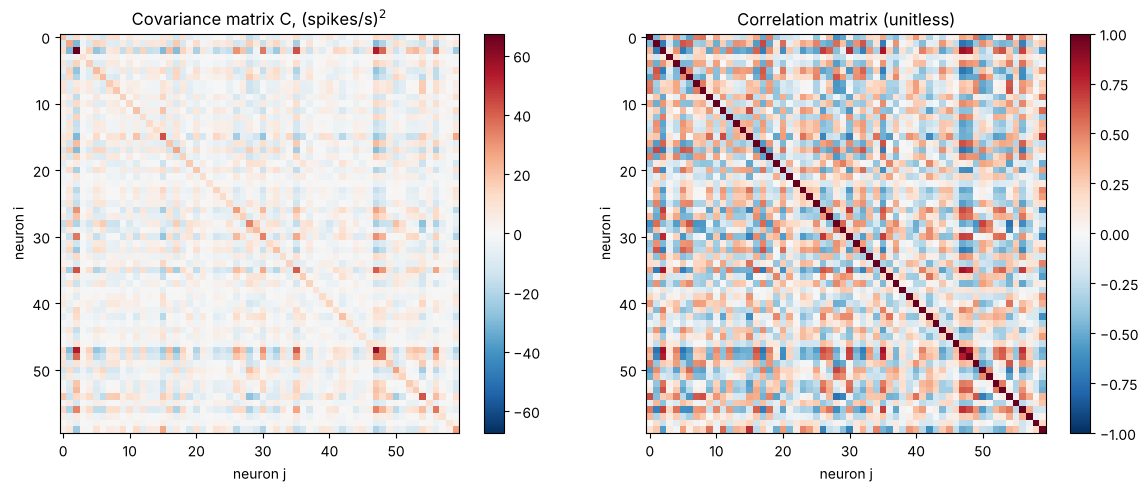

In [5]:
Xc_sim = X_sim - X_sim.mean(axis=0)                  # centred, shape (600, 60)
C_sim = Xc_sim.T @ Xc_sim / (T_sim - 1)               # covariance, shape (60, 60), (spikes/s)^2
print("matches np.cov?", np.allclose(C_sim, np.cov(X_sim, rowvar=False)))   # rowvar=False: columns are variables
print("symmetric?", np.allclose(C_sim, C_sim.T), "  smallest eigenvalue:", f"{np.linalg.eigvalsh(C_sim).min():.3f}  (>= 0)")
R_sim = np.corrcoef(X_sim, rowvar=False)              # correlation, shape (60, 60), unitless

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
lim = np.abs(C_sim).max()
im0 = axes[0].imshow(C_sim, cmap='RdBu_r', vmin=-lim, vmax=lim); axes[0].set_title('Covariance matrix C, (spikes/s)$^2$')
im1 = axes[1].imshow(R_sim, cmap='RdBu_r', vmin=-1, vmax=1); axes[1].set_title('Correlation matrix (unitless)')
for ax, im in zip(axes, [im0, im1]):
    ax.set_xlabel('neuron j'); ax.set_ylabel('neuron i'); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

The blocks of red and blue are neurons that share the hidden signals with the same or opposite sign. The structure is visible here even though it was invisible in the raw heatmap.

### Variance along any direction

Project each centred time bin onto a unit vector $\mathbf{u}$ (Lesson 2): the score $y_t = \mathbf{u}^{\mathsf T}(\mathbf{x}_t - \bar{\mathbf{x}})$, i.e. $\mathbf{y} = \mathbf{X}_c\mathbf{u}$. Its variance is

$$\operatorname{Var}(y) = \frac{1}{n-1}\mathbf{u}^{\mathsf T}\mathbf{X}_c^{\mathsf T}\mathbf{X}_c\,\mathbf{u} = \mathbf{u}^{\mathsf T}\mathbf{C}\,\mathbf{u}.$$

So **the covariance matrix gives the variance along every direction**, not just along the axes. This is the Rayleigh quotient of Lesson 6, and it is the key to PCA. The animation sweeps $\mathbf{u}$ round the circle for two neurons.

In [6]:
C2 = np.cov(pair, rowvar=False)                       # 2x2 covariance of neurons 0 and 1
angles = np.arange(0, 180, 5)
var_along = [np.array([np.cos(np.radians(a)), np.sin(np.radians(a))]) @ C2 @ np.array([np.cos(np.radians(a)), np.sin(np.radians(a))]) for a in angles]
print(f"variance along the axes: {C2[0, 0]:.1f}, {C2[1, 1]:.1f} (spikes/s)^2;  largest over all directions: {max(var_along):.1f} at {angles[np.argmax(var_along)]} deg")

def frame_data(a):
    u = np.array([np.cos(np.radians(a)), np.sin(np.radians(a))])
    proj = np.round(np.outer(pair_c[::2] @ u, u), 2)   # the projected points (every 2nd bin, to keep the file small), shape (300, 2)
    return u, proj
u0, p0 = frame_data(0)
fig_var = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], subplot_titles=('centred data and its projection onto u', 'variance along u'))
fig_var.add_trace(go.Scatter(x=np.round(pair_c[::2, 0], 2), y=np.round(pair_c[::2, 1], 2), mode='markers', marker=dict(size=4, color=PALETTE[0], opacity=0.35), name='centred data'), 1, 1)
fig_var.add_trace(go.Scatter(x=p0[:, 0], y=p0[:, 1], mode='markers', marker=dict(size=4, color=PALETTE[1]), name='projection onto u'), 1, 1)
fig_var.add_trace(go.Scatter(x=angles, y=var_along, mode='lines', line=dict(color='grey'), name='u^T C u'), 1, 2)
fig_var.add_trace(go.Scatter(x=[0], y=[var_along[0]], mode='markers', marker=dict(size=12, color=PALETTE[1]), name='current u'), 1, 2)
fig_var.frames = [go.Frame(name=str(k), traces=[1, 3], data=[go.Scatter(x=frame_data(a)[1][:, 0], y=frame_data(a)[1][:, 1]),
                                                             go.Scatter(x=[a], y=[var_along[k]])])
                  for k, a in enumerate(angles)]
buttons, sliders = play_pause_and_slider([str(a) for a in angles], prefix='direction of u (deg) = ', duration=200)
lim2 = 1.1 * np.abs(pair_c).max()
fig_var.update_xaxes(title_text='neuron 0 (spikes/s)', range=[-lim2, lim2], row=1, col=1)
fig_var.update_yaxes(title_text='neuron 1 (spikes/s)', range=[-lim2, lim2], scaleanchor='x', scaleratio=1, row=1, col=1)
fig_var.update_xaxes(title_text='angle of u (deg)', row=1, col=2); fig_var.update_yaxes(title_text='variance (spikes/s)^2', row=1, col=2)
fig_var.update_layout(template='plotly_white', width=980, height=520, updatemenus=buttons, sliders=sliders)
fig_var.show(config=PLOTLY_CONFIG)

variance along the axes: 20.2, 26.0 (spikes/s)^2;  largest over all directions: 33.6 at 125 deg


# **Part 3: Principal Axes — the Eigenvectors of the Covariance Matrix**

Which unit vector $\mathbf{u}$ makes $\mathbf{u}^{\mathsf T}\mathbf{C}\mathbf{u}$ largest? Lesson 6 answered this for any symmetric matrix: the **top eigenvector**, and the maximum value is the **top eigenvalue**. The next best direction, orthogonal to the first, is the second eigenvector, and so on.

**PCA in four steps:**
1. Centre: $\mathbf{X}_c = \mathbf{X} - \bar{\mathbf{x}}$.
2. Covariance: $\mathbf{C} = \mathbf{X}_c^{\mathsf T}\mathbf{X}_c/(n-1)$.
3. Eigen-decompose $\mathbf{C} = \mathbf{Q}\boldsymbol\Lambda\mathbf{Q}^{\mathsf T}$ and **order** the eigenvalues from largest to smallest, $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_N \ge 0$ (`np.linalg.eigh` returns them smallest first, so reverse).
4. Project: $\mathbf{S} = \mathbf{X}_c\mathbf{Q}$.

| Name | Symbol, shape | Meaning |
|---|---|---|
| **principal axes / components** | columns $\mathbf{q}_k$ of $\mathbf{Q}$, $(N, N)$ | orthonormal directions in neuron space, ordered by variance |
| **loadings** | entries $Q_{ik}$ | how much neuron $i$ contributes to component $k$ (unitless weights) |
| **scores** | $\mathbf{S} = \mathbf{X}_c\mathbf{Q}$, $(n, N)$ | each time bin's coordinates along the components, in spikes/s |
| **eigenvalues** | $\lambda_k$ | the variance of the scores on component $k$, (spikes/s)$^2$ |

(Some texts and libraries scale loadings by $\sqrt{\lambda_k}$; here a loading is an entry of the unit vector $\mathbf{q}_k$.)

eigenvalues (spikes/s)^2: [33.68 12.56]   sum: 46.24 = total variance 46.24
components (columns):
 [[-0.603 -0.797]
 [ 0.797 -0.603]]
variance of the scores: [33.68 12.56]   covariance between scores: 1.5e-15


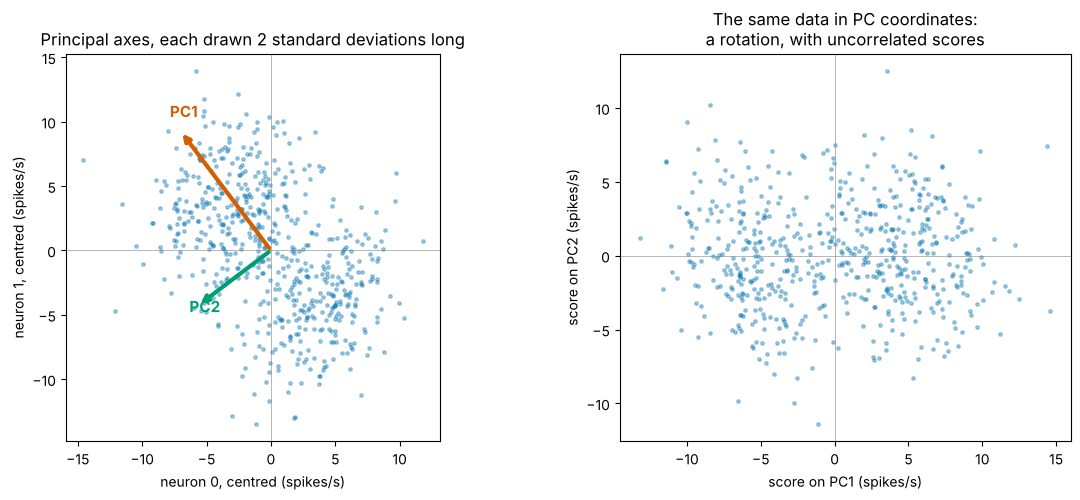

In [7]:
def pca(X):
    # Principal component analysis of a (samples x variables) matrix.
    # Returns (eigenvalues in decreasing order, components as columns, scores, mean).
    mean = X.mean(axis=0)
    Xc = X - mean
    lam, Q = np.linalg.eigh(Xc.T @ Xc / (X.shape[0] - 1))
    order = np.argsort(lam)[::-1]
    lam, Q = lam[order], Q[:, order]
    return lam, Q, Xc @ Q, mean

lam2, Q2, S2, _ = pca(pair)
print("eigenvalues (spikes/s)^2:", np.round(lam2, 2), "  sum:", round(lam2.sum(), 2), "= total variance", round(np.trace(C2), 2))
print("components (columns):\n", np.round(Q2, 3))
print("variance of the scores:", np.round(S2.var(axis=0, ddof=1), 2), "  covariance between scores:", f"{np.cov(S2, rowvar=False)[0, 1]:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.scatter(pair_c[:, 0], pair_c[:, 1], s=6, alpha=0.35, color=PALETTE[0])
for k, colour in enumerate([PALETTE[1], PALETTE[2]]):
    v = Q2[:, k] * 2 * np.sqrt(lam2[k])
    ax.annotate('', xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=colour, lw=3))
    ax.text(*(v * 1.12), f'PC{k + 1}', color=colour, fontsize=11, fontweight='bold')
ax.set_aspect('equal'); ax.set_xlabel('neuron 0, centred (spikes/s)'); ax.set_ylabel('neuron 1, centred (spikes/s)')
ax.set_title('Principal axes, each drawn 2 standard deviations long')
axes[1].scatter(S2[:, 0], S2[:, 1], s=6, alpha=0.35, color=PALETTE[0])
axes[1].set_aspect('equal'); axes[1].set_xlabel('score on PC1 (spikes/s)'); axes[1].set_ylabel('score on PC2 (spikes/s)')
axes[1].set_title('The same data in PC coordinates:\na rotation, with uncorrelated scores')
for ax in axes:
    ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
plt.tight_layout()
plt.show()

Three facts to notice, each proved in the notes:
- the eigenvalues add up to the **total variance**, $\sum_k\lambda_k = \operatorname{tr}\mathbf{C} = \sum_i s_i^2$, so PCA redistributes the variance without creating or losing any;
- the score on component $k$ has variance exactly $\lambda_k$;
- scores on different components are **uncorrelated**: in PC coordinates the covariance matrix is diagonal.

Since $\mathbf{Q}$ is orthogonal, the change to scores is a pure rotation (possibly with a reflection) of the centred cloud (Lesson 4).

### Sign indeterminacy

If $\mathbf{q}$ is an eigenvector, so is $-\mathbf{q}$ (Lesson 6). PCA cannot choose between them: a component and its negative explain the same variance, and flipping a component flips the sign of its scores and loadings together. Different software, or the same software on slightly different data, can return either sign. **Never interpret the sign of a component on its own**; interpret the sign of a loading relative to the others, or fix a convention (for example, make the largest loading positive).

In [8]:
Q_flip = Q2 * np.array([-1, 1])                       # flip PC1
S_flip = pair_c @ Q_flip
print("PC1 scores, first 3 bins, original:", np.round(S2[:3, 0], 2), "  flipped:", np.round(S_flip[:3, 0], 2))
print("same variance?", np.allclose(S_flip.var(axis=0, ddof=1), lam2))
print("same reconstruction of the data?", np.allclose(S_flip @ Q_flip.T, S2 @ Q2.T))

def fix_signs(Q):
    # Convention: make the largest-magnitude loading of each component positive.
    idx = np.argmax(np.abs(Q), axis=0)
    return Q * np.sign(Q[idx, np.arange(Q.shape[1])])
print("after the convention, original and flipped agree:", np.allclose(fix_signs(Q2), fix_signs(Q_flip)))

PC1 scores, first 3 bins, original: [6.63 2.97 7.72]   flipped: [-6.63 -2.97 -7.72]
same variance? True
same reconstruction of the data? True
after the convention, original and flipped agree: True


# **Part 4: Projection, Low-Rank Reconstruction and Explained Variance**

Keep only the first $k$ components, $\mathbf{Q}_k$ of shape $(N, k)$. The **projection** $\mathbf{S}_k = \mathbf{X}_c\mathbf{Q}_k$ gives $k$ numbers per time bin instead of $N$. Mapping back,

$$\hat{\mathbf{X}} = \bar{\mathbf{x}} + \mathbf{S}_k\mathbf{Q}_k^{\mathsf T} = \bar{\mathbf{x}} + \mathbf{X}_c\mathbf{Q}_k\mathbf{Q}_k^{\mathsf T},$$

is the **rank-$k$ reconstruction**: each centred time bin is projected onto the $k$-dimensional subspace spanned by the top components (the projection matrix $\mathbf{Q}_k\mathbf{Q}_k^{\mathsf T}$ of Lesson 5, with orthonormal columns). Among all rank-$k$ subspaces, this one gives the smallest total squared reconstruction error, and that error equals the variance thrown away: $(n-1)\sum_{j>k}\lambda_j$.

The **explained-variance ratio** of component $k$ is $\lambda_k / \sum_j\lambda_j$. A **scree plot** shows these ratios in order; its name comes from the rubble at the foot of a cliff. Look for the "elbow" where the cliff turns into rubble.

explained-variance ratio of the first 5 components: [0.377 0.192 0.012 0.012 0.012]
first two together: 56.9%;  each remaining component: about 0.74%
noise variance per neuron: 9.0; median of the trailing eigenvalues: 8.83 (spikes/s)^2


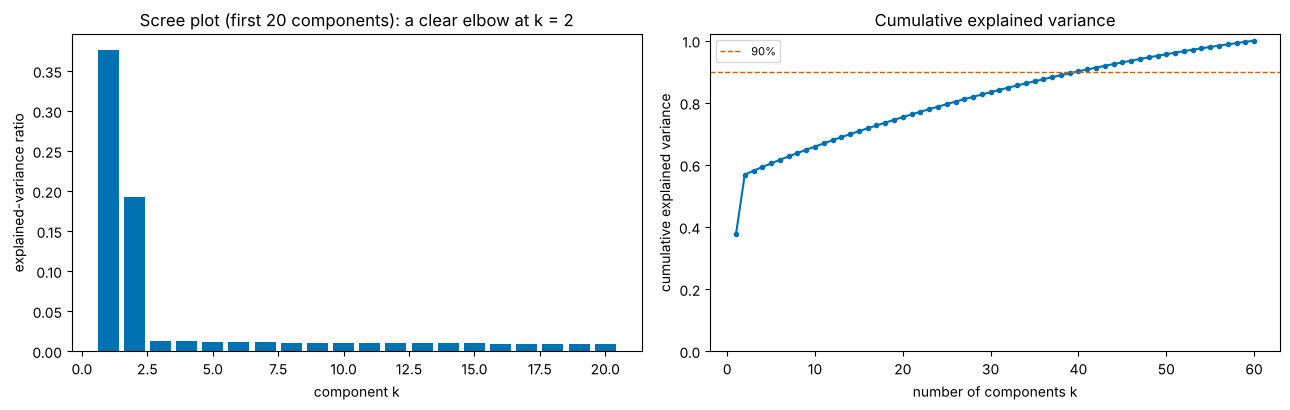

In [9]:
lam_sim, Q_sim, S_sim, mean_sim = pca(X_sim)
evr = lam_sim / lam_sim.sum()
print("explained-variance ratio of the first 5 components:", np.round(evr[:5], 3))
print(f"first two together: {evr[:2].sum():.1%};  each remaining component: about {evr[2:].mean():.2%}")
print(f"noise variance per neuron: {noise_sd**2:.1f}; median of the trailing eigenvalues: {np.median(lam_sim[2:]):.2f} (spikes/s)^2")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ks = np.arange(1, N_sim + 1)
axes[0].bar(ks[:20], evr[:20], color=PALETTE[0])
axes[0].set_xlabel('component k'); axes[0].set_ylabel('explained-variance ratio'); axes[0].set_title('Scree plot (first 20 components): a clear elbow at k = 2')
axes[1].plot(ks, np.cumsum(evr), 'o-', ms=3, color=PALETTE[0])
axes[1].axhline(0.9, color=PALETTE[1], ls='--', lw=1, label='90%')
axes[1].set_xlabel('number of components k'); axes[1].set_ylabel('cumulative explained variance'); axes[1].set_ylim(0, 1.02)
axes[1].set_title('Cumulative explained variance'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Two components carry most of the variance, and the remaining 58 each carry about the same small amount: the **noise floor**. With independent noise of variance $\sigma^2$ in every neuron, the noise adds roughly $\sigma^2$ to every eigenvalue, so the trailing eigenvalues sit near $\sigma^2 = 9$ (they spread a little around it because they are estimated from finite data).

Did PCA find the hidden signals? The top two scores should be mixtures of $z_1$ and $z_2$ (PCA finds the **subspace**, but any rotation within it explains the same variance, so the individual components need not equal the original signals one-for-one). Least squares (Lesson 5) tells us how well the two scores explain each hidden signal.

hidden signal 1 explained by the top two scores: R^2 = 0.971
hidden signal 2 explained by the top two scores: R^2 = 0.975


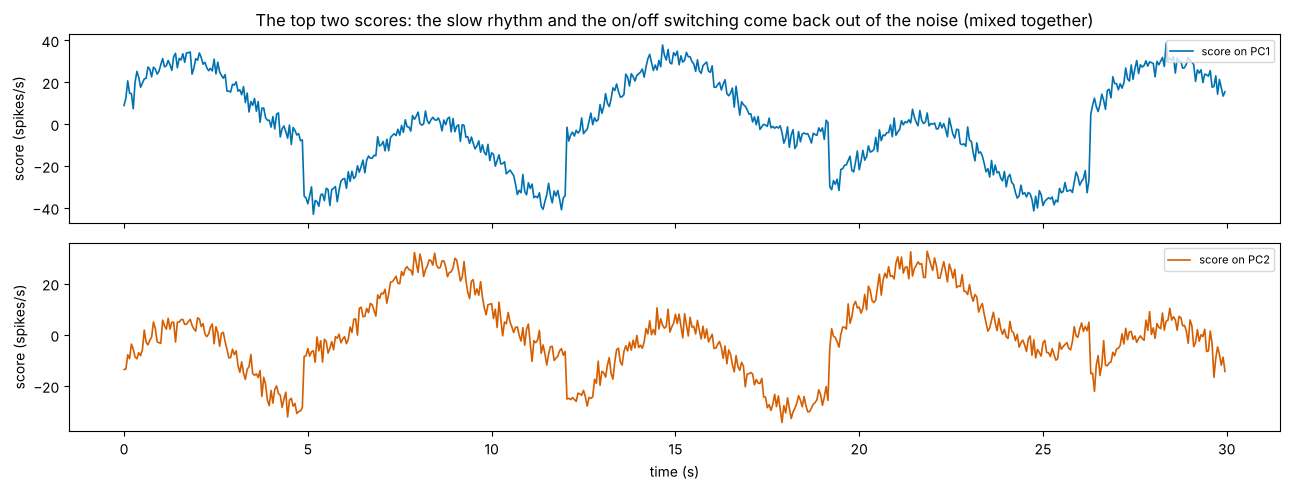

In [10]:
S_top = S_sim[:, :2]                                            # shape (600, 2), spikes/s
for j in range(2):
    D = np.column_stack([np.ones(T_sim), S_top])
    beta = np.linalg.lstsq(D, z_true[:, j], rcond=None)[0]
    r2 = 1 - np.sum((z_true[:, j] - D @ beta)**2) / np.sum((z_true[:, j] - z_true[:, j].mean())**2)
    print(f"hidden signal {j + 1} explained by the top two scores: R^2 = {r2:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(t_sim, S_sim[:, k], color=PALETTE[k], lw=1.2, label=f'score on PC{k + 1}')
    ax.set_ylabel('score (spikes/s)'); ax.legend(fontsize=8, loc='upper right')
axes[0].set_title('The top two scores: the slow rhythm and the on/off switching come back out of the noise (mixed together)')
axes[1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

#### Interactive version: reconstruct the population with k components

Drag the slider. With $k = 0$ every neuron sits at its mean. By $k = 2$ the structure is all there; further components mostly add back noise.

In [11]:
k_values = [0, 1, 2, 3, 5, 10, 20, 60]
def reconstruct(k):
    return mean_sim + S_sim[:, :k] @ Q_sim[:, :k].T             # shape (600, 60)
def heat(k):
    return reconstruct(k)[::4].T.astype(np.float32)               # every 4th bin, single precision: keeps the file small
fig_rec = go.Figure(go.Heatmap(z=heat(0), x=t_sim[::4], colorscale='Viridis', zmin=X_sim.min(), zmax=X_sim.max(), colorbar=dict(title='spikes/s')))
fig_rec.frames = [go.Frame(name=str(i), data=[go.Heatmap(z=heat(k))],
                           layout=go.Layout(title=f'rank-{k} reconstruction: {np.cumsum(np.r_[0, evr])[k]:.1%} of the variance'))
                  for i, k in enumerate(k_values)]
buttons, sliders = play_pause_and_slider(k_values, prefix='components kept k = ', duration=700)
fig_rec.update_layout(title=fig_rec.frames[0].layout.title.text, xaxis_title='time (s)', yaxis_title='neuron', template='plotly_white',
                      width=900, height=480, updatemenus=buttons, sliders=sliders)
fig_rec.show(config=PLOTLY_CONFIG)

### PCA through the singular value decomposition

In practice PCA is usually computed from the **singular value decomposition** of the centred data, $\mathbf{X}_c = \mathbf{U}\boldsymbol\Sigma\mathbf{V}^{\mathsf T}$, without forming $\mathbf{C}$ at all. The columns of $\mathbf{V}$ are the principal components, and $\lambda_k = \sigma_k^2/(n-1)$. It is more accurate (forming $\mathbf{X}_c^{\mathsf T}\mathbf{X}_c$ squares the condition number, as in Lesson 5) and is what `sklearn.decomposition.PCA` does. The bonus exercise proves the link.

In [12]:
U, sing, Vt = np.linalg.svd(X_sim - X_sim.mean(axis=0), full_matrices=False)
print("eigenvalues from SVD match?", np.allclose(sing**2 / (T_sim - 1), lam_sim))
print("components match up to sign?", np.allclose(np.abs(Vt[:5].T), np.abs(Q_sim[:, :5])))

eigenvalues from SVD match? True
components match up to sign? True


# **Part 5: Scale Sensitivity and Standardisation**

PCA maximises variance, and variance depends on **units**. Suppose each time bin records a neuron's rate (spikes/s), the pupil diameter (mm) and running speed. Measure speed in cm/s and it has a huge variance; measure it in m/s and its variance is $10^4$ times smaller. Same data, different first component.

The usual fix is to **standardise** each variable, dividing its centred values by its standard deviation (z-scores, unitless). PCA of standardised data is the eigen-decomposition of the **correlation** matrix. Every variable then starts with variance 1, so none dominates through its units.

speed in cm/s  raw PC1 loadings (rate, pupil, speed) = [0.17 0.02 0.99]  (88%)   standardised PC1 = [0.63 0.62 0.47]  (64%)
speed in m/s   raw PC1 loadings (rate, pupil, speed) = [1.   0.1  0.01]  (99%)   standardised PC1 = [0.63 0.62 0.47]  (64%)


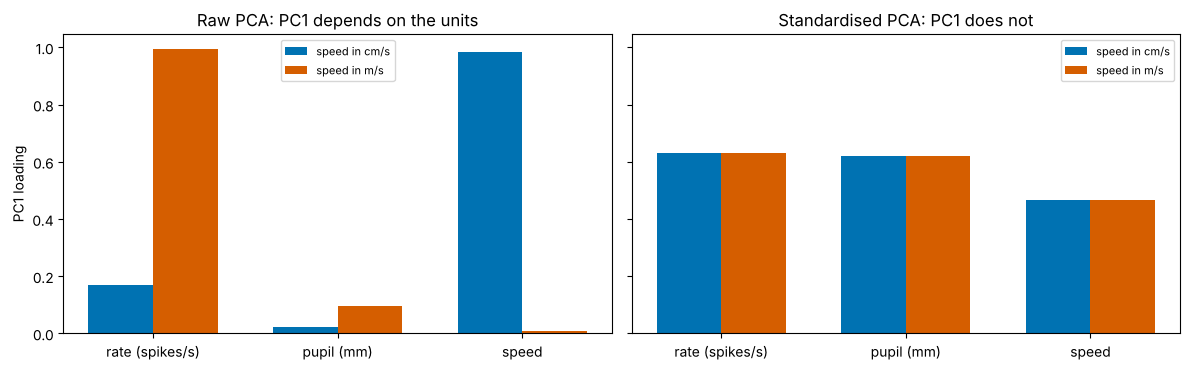

In [13]:
n5 = 800
arousal = RNG.normal(size=n5)                               # a shared hidden 'arousal' state, unitless
rate5 = 12 + 3 * arousal + RNG.normal(0, 2, n5)              # spikes/s
pupil5 = 4 + 0.4 * arousal + RNG.normal(0, 0.3, n5)          # mm
speed_cm = 10 + 4 * arousal + RNG.normal(0, 8, n5)           # cm/s: mostly its own variability
names5 = ['rate (spikes/s)', 'pupil (mm)', 'speed']

rows = []
for label, speed in [('speed in cm/s', speed_cm), ('speed in m/s', speed_cm / 100)]:
    D5 = np.column_stack([rate5, pupil5, speed])
    lam_raw, Q_raw, _, _ = pca(D5)
    Z5 = (D5 - D5.mean(axis=0)) / D5.std(axis=0, ddof=1)
    lam_z, Q_z, _, _ = pca(Z5)
    rows.append((label, fix_signs(Q_raw)[:, 0], lam_raw[0] / lam_raw.sum(), fix_signs(Q_z)[:, 0], lam_z[0] / lam_z.sum()))
for label, q_raw, e_raw, q_z, e_z in rows:
    print(f"{label:<14} raw PC1 loadings (rate, pupil, speed) = {np.round(q_raw, 2)}  ({e_raw:.0%})   standardised PC1 = {np.round(q_z, 2)}  ({e_z:.0%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
xpos = np.arange(3)
for ax, which, title in [(axes[0], 1, 'Raw PCA: PC1 depends on the units'), (axes[1], 3, 'Standardised PCA: PC1 does not')]:
    for j, (label, *vals) in enumerate(rows):
        ax.bar(xpos + (j - 0.5) * 0.35, vals[which - 1], width=0.35, color=PALETTE[j], label=label)
    ax.set_xticks(xpos); ax.set_xticklabels(names5); ax.axhline(0, color='grey', lw=0.5)
    ax.set_title(title); ax.legend(fontsize=8)
axes[0].set_ylabel('PC1 loading')
plt.tight_layout()
plt.show()

In cm/s, speed dominates the raw PC1 although most of its variability has nothing to do with arousal. In m/s, speed nearly vanishes and the firing rate takes over. Standardised PCA gives the same answer in both units and finds the shared arousal pattern: all three variables load with the same sign.

**When to standardise.**
- Variables in **different units** (rate, pupil, speed; or features in a machine-learning table): standardise.
- Variables in the **same units** where size matters (rates of neurons in spikes/s): often do **not** standardise, because a neuron that varies by 20 spikes/s really does carry more signal than one that varies by 0.5. But then PCA is dominated by high-rate neurons, which may not be what you want.
- Standardising a nearly silent neuron blows its noise up to variance 1, as much as a strongly modulated neuron. A common compromise in neuroscience is **soft normalisation**, dividing by (range + a constant).

There is no automatic right answer. It is a modelling choice, and it should be reported.

# **Part 6: Leakage — Fit PCA on Training Data Only**

PCA is often a preprocessing step before a model is fitted and tested (Lesson 5's train/test split). The mean, the scaling and the components are all **estimated from data**, so they must be estimated from the **training data only** and then applied unchanged to the test data. Fitting PCA on all the data lets the test set shape the components, which is **leakage**, and it makes test performance look better than it will be on genuinely new data.

The effect is largest when there are many variables and few samples. Below: 100 neurons, 60 training trials and 60 test trials, from a population with 5 real dimensions. We ask what fraction of the **test** variance 10 components capture.

test variance captured by 10 components, PCA fitted on training data only: 0.536
                                         PCA fitted on training + test   : 0.650   (leaky, optimistic)


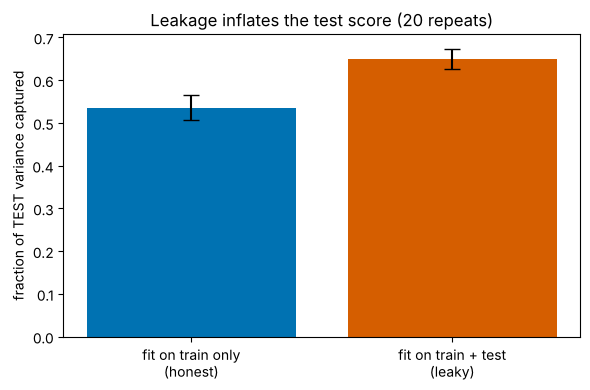

In [14]:
def leakage_demo(n_train=60, n_test=60, N=100, rank=5, seed=0):
    rng = np.random.default_rng(seed)
    L = rng.normal(size=(N, rank))
    def sample(n):
        return rng.normal(size=(n, rank)) @ L.T + rng.normal(0, 2.0, size=(n, N))
    Xtr, Xte = sample(n_train), sample(n_test)
    def test_ev(fit_on, k=10):
        _, Q, _, mu = pca(fit_on)
        Xc_te = Xte - mu
        resid = Xc_te - Xc_te @ Q[:, :k] @ Q[:, :k].T
        return 1 - np.sum(resid**2) / np.sum((Xte - Xte.mean(axis=0))**2)
    return test_ev(Xtr), test_ev(np.vstack([Xtr, Xte]))

res = np.array([leakage_demo(seed=s) for s in range(20)])
print(f"test variance captured by 10 components, PCA fitted on training data only: {res[:, 0].mean():.3f}")
print(f"                                         PCA fitted on training + test   : {res[:, 1].mean():.3f}   (leaky, optimistic)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([0, 1], res.mean(axis=0), yerr=res.std(axis=0), color=[PALETTE[0], PALETTE[1]], capsize=6)
ax.set_xticks([0, 1]); ax.set_xticklabels(['fit on train only\n(honest)', 'fit on train + test\n(leaky)'])
ax.set_ylabel('fraction of TEST variance captured'); ax.set_title('Leakage inflates the test score (20 repeats)')
plt.tight_layout()
plt.show()

The same rule covers every preprocessing step: centring means, standardisation scales, component directions, the number of components chosen by cross-validation. The safe pattern is always: **fit on train, apply to test.** In scikit-learn this is `PCA().fit(X_train)` followed by `.transform(X_test)`, ideally inside a `Pipeline`.

# **Part 7: Denoising with a Low-Rank Reconstruction**

If the signal lives in a few dimensions and the noise spreads evenly over all of them, keeping the top $k$ components keeps nearly all the signal and only a fraction $k/N$ of the noise. Because we simulated the data, we know the noise-free rates and can measure how close each reconstruction is to the truth.

RMS error of the raw data against the truth: 3.01 spikes/s
best reconstruction: k = 2, RMS error 0.58 spikes/s


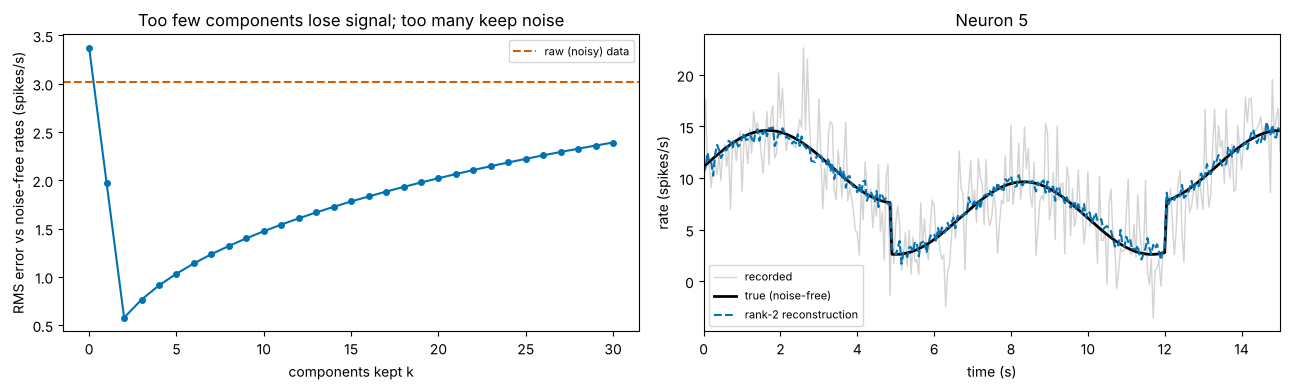

In [15]:
X_clean = baseline + z_true @ W_true.T                          # the noise-free rates, shape (600, 60)
ks7 = np.arange(0, 31)
err = [np.sqrt(np.mean((reconstruct(k) - X_clean)**2)) for k in ks7]
print(f"RMS error of the raw data against the truth: {np.sqrt(np.mean((X_sim - X_clean)**2)):.2f} spikes/s")
print(f"best reconstruction: k = {ks7[np.argmin(err)]}, RMS error {min(err):.2f} spikes/s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks7, err, 'o-', ms=4, color=PALETTE[0])
axes[0].axhline(np.sqrt(np.mean((X_sim - X_clean)**2)), color=PALETTE[1], ls='--', label='raw (noisy) data')
axes[0].set_xlabel('components kept k'); axes[0].set_ylabel('RMS error vs noise-free rates (spikes/s)')
axes[0].set_title('Too few components lose signal; too many keep noise'); axes[0].legend(fontsize=8)
i = 5
axes[1].plot(t_sim, X_sim[:, i], color='lightgrey', lw=1, label='recorded')
axes[1].plot(t_sim, X_clean[:, i], color='black', lw=2, label='true (noise-free)')
axes[1].plot(t_sim, reconstruct(2)[:, i], color=PALETTE[0], lw=1.5, ls='--', label='rank-2 reconstruction')
axes[1].set_xlim(0, 15); axes[1].set_xlabel('time (s)'); axes[1].set_ylabel('rate (spikes/s)'); axes[1].set_title(f'Neuron {i}'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

With real data there is no noise-free truth to compare against, and $k$ must be chosen another way: from the scree elbow, from a target cumulative variance, or (best) by cross-validation on held-out data.

# **Part 8: Limitations of PCA**

PCA is the first thing to try, not the last word. Four limitations matter in practice.

1. **Variance is not importance.** PCA never sees labels or behaviour. If two conditions differ along a low-variance direction, PCA can throw that direction away.
2. **PCA is linear.** It finds flat subspaces. Activity on a curved manifold (a ring of head-direction cells, say) needs more components than its true dimension.
3. **Equal eigenvalues make components arbitrary.** If $\lambda_1 \approx \lambda_2$, any rotation within their plane is equally good, and the individual components are unstable from sample to sample. Only the plane is meaningful.
4. **Sensitivity to scale and outliers.** Part 5 showed scale; a few extreme time bins (artefacts) can also capture a whole component, because squared deviations weigh them heavily.

The first two are shown below.

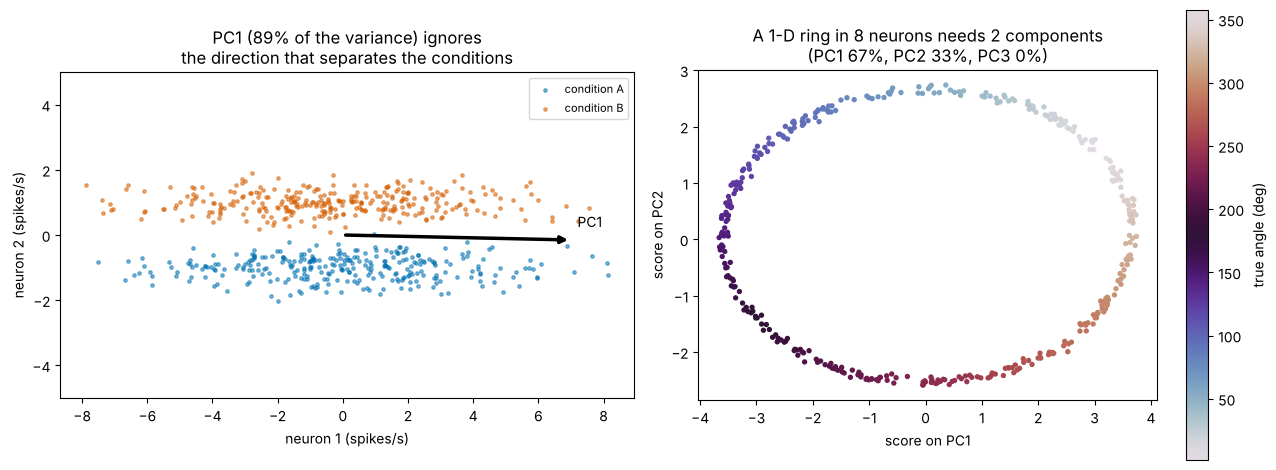

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
# 1. A low-variance direction carries the label
n8 = 300
big = RNG.normal(0, 3, size=2 * n8)
small = np.r_[RNG.normal(-1.0, 0.35, n8), RNG.normal(1.0, 0.35, n8)]
labels8 = np.r_[np.zeros(n8), np.ones(n8)]
X8 = np.column_stack([big, small])
lam8, Q8, S8, _ = pca(X8)
for c, colour, name in [(0, PALETTE[0], 'condition A'), (1, PALETTE[1], 'condition B')]:
    axes[0].scatter(X8[labels8 == c, 0], X8[labels8 == c, 1], s=6, alpha=0.5, color=colour, label=name)
q8 = Q8[:, 0] * np.sign(Q8[0, 0])
axes[0].annotate('', xy=q8 * 7, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='black', lw=2.5))
axes[0].text(*(q8 * 7 + [0.2, 0.4]), 'PC1', fontsize=10)
axes[0].set_aspect('equal'); axes[0].set_ylim(-5, 5); axes[0].set_xlabel('neuron 1 (spikes/s)'); axes[0].set_ylabel('neuron 2 (spikes/s)')
axes[0].set_title(f'PC1 ({lam8[0] / lam8.sum():.0%} of the variance) ignores\nthe direction that separates the conditions'); axes[0].legend(fontsize=8)

# 2. A one-dimensional ring needs two components
theta = RNG.uniform(0, 2 * np.pi, 400)
ring = np.column_stack([np.cos(theta), np.sin(theta), 0.3 * np.cos(theta)]) @ RNG.normal(size=(3, 8)) + RNG.normal(0, 0.05, (400, 8))
lam_r, _, S_r, _ = pca(ring)
sc = axes[1].scatter(S_r[:, 0], S_r[:, 1], c=np.degrees(theta), cmap='twilight', s=8)
plt.colorbar(sc, ax=axes[1], label='true angle (deg)')
axes[1].set_aspect('equal'); axes[1].set_xlabel('score on PC1'); axes[1].set_ylabel('score on PC2')
axes[1].set_title('A 1-D ring in 8 neurons needs 2 components\n(PC1 {:.0%}, PC2 {:.0%}, PC3 {:.0%})'.format(*(lam_r[:3] / lam_r.sum())))
plt.tight_layout()
plt.show()

For problem 1, a method that uses the labels, such as linear discriminant analysis or a decoder (Lesson 5), is the right tool. For problem 2, nonlinear methods (Isomap, UMAP, autoencoders) exist, but PCA remains the baseline every one of them must beat.

# **Part 9: Mini-Lab — The Dominant Patterns of Motor Cortex**

We return to the recording of Lessons 2, 4, 5 and 6: 171 neurons in monkey primary motor cortex during centre-out reaches, in 50 ms bins ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)).

**Plan.**
1. Smooth each neuron's rate (Gaussian, standard deviation 2 bins = 100 ms), and drop neurons that are silent in the training half.
2. Fit PCA on the **first half** only (training); apply it unchanged to the second half (test).
3. Read the scree plot, and compare raw with standardised PCA.
4. Ask whether the top components relate to the movement: their average scores by reach direction, and how well hand velocity can be decoded from the top $k$ scores (Lesson 5's least squares).

In [17]:
import os, urllib.request
from scipy.io import loadmat

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
rates = m1['spikes'].T.astype(float) / 0.05                     # shape (15536, 171): (time bin, neuron), spikes/s
vel = m1['handVel'][:2].T * 100                                   # shape (15536, 2): hand velocity (vx, vy), cm/s
T_m1 = rates.shape[0]
train = np.arange(T_m1) < T_m1 // 2                               # first half for fitting, second half for testing

def smooth(R, sigma_bins):
    k = np.exp(-0.5 * (np.arange(-4 * sigma_bins, 4 * sigma_bins + 1) / sigma_bins)**2); k /= k.sum()
    return np.apply_along_axis(lambda x: np.convolve(x, k, mode='same'), 0, R)

Zm = smooth(rates, 2)
active = Zm[train].std(axis=0) > 0                                # drop neurons silent throughout the training half
Zm = Zm[:, active]
print("data:", Zm.shape, "(time bin, neuron), spikes/s;  neurons dropped as silent in training:", int((~active).sum()))

# Fit PCA on the TRAINING half only.
lam_m1, Q_m1, _, mu_m1 = pca(Zm[train])
scores_m1 = (Zm - mu_m1) @ Q_m1                                   # apply to all bins with the TRAINING mean and components
evr_m1 = lam_m1 / lam_m1.sum()
cum_m1 = np.cumsum(evr_m1)
print("explained-variance ratio, first 5 components:", np.round(evr_m1[:5], 3))
for target in [0.5, 0.8, 0.9]:
    print(f"components needed for {target:.0%} of the training variance: {np.searchsorted(cum_m1, target) + 1}")

def test_fraction(k, Q=Q_m1, mu=mu_m1, Z=Zm):
    Xte = Z[~train] - mu
    resid = Xte - Xte @ Q[:, :k] @ Q[:, :k].T
    return 1 - np.sum(resid**2) / np.sum((Z[~train] - Z[~train].mean(axis=0))**2)
for k in [5, 10, 50]:
    print(f"k = {k:>2}: training variance {cum_m1[k - 1]:.3f}, test variance captured {test_fraction(k):.3f}")

data: (15536, 170) (time bin, neuron), spikes/s;  neurons dropped as silent in training: 1
explained-variance ratio, first 5 components: [0.166 0.119 0.059 0.051 0.04 ]
components needed for 50% of the training variance: 8
components needed for 80% of the training variance: 36
components needed for 90% of the training variance: 62
k =  5: training variance 0.434, test variance captured 0.331
k = 10: training variance 0.568, test variance captured 0.470
k = 50: training variance 0.863, test variance captured 0.782


correlation between |PC1 loading| and mean rate: raw 0.67, standardised 0.10
components for 80% of the variance: raw 36, standardised 83


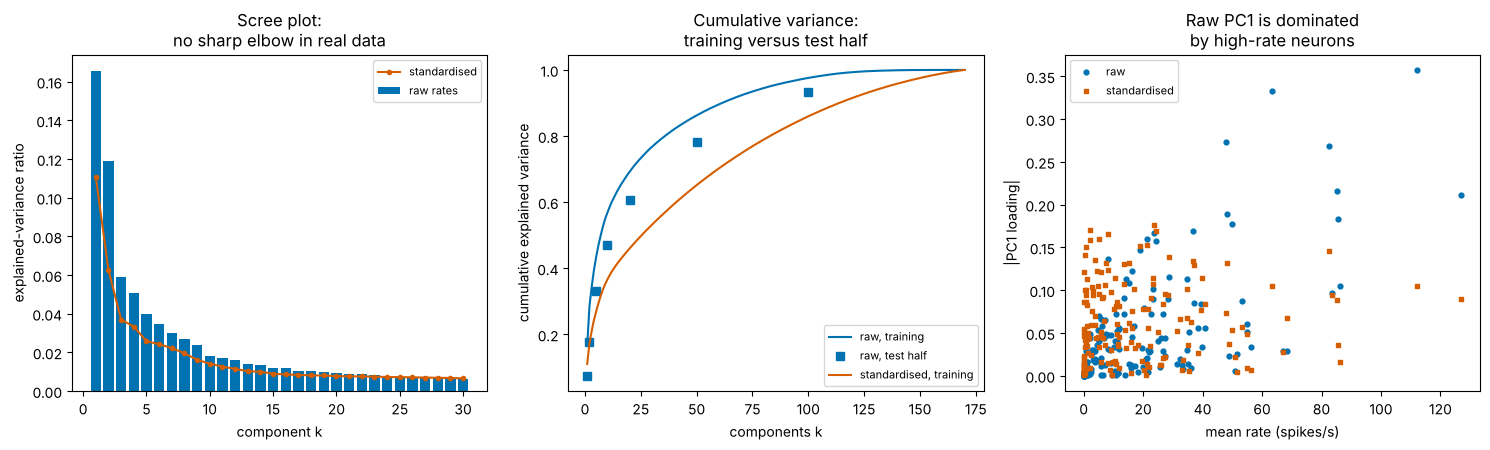

In [18]:
# Raw versus standardised: which neurons dominate PC1?
mean_rate = Zm[train].mean(axis=0)
sd_m1 = Zm[train].std(axis=0, ddof=1)
lam_z1, Q_z1, _, _ = pca((Zm[train] - mu_m1) / sd_m1)
evr_z1 = lam_z1 / lam_z1.sum()
print(f"correlation between |PC1 loading| and mean rate: raw {np.corrcoef(np.abs(Q_m1[:, 0]), mean_rate)[0, 1]:.2f}, standardised {np.corrcoef(np.abs(Q_z1[:, 0]), mean_rate)[0, 1]:.2f}")
print(f"components for 80% of the variance: raw {np.searchsorted(cum_m1, 0.8) + 1}, standardised {np.searchsorted(np.cumsum(evr_z1), 0.8) + 1}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
kk = np.arange(1, 31)
axes[0].bar(kk, evr_m1[:30], color=PALETTE[0], label='raw rates')
axes[0].plot(kk, evr_z1[:30], 'o-', ms=3, color=PALETTE[1], label='standardised')
axes[0].set_xlabel('component k'); axes[0].set_ylabel('explained-variance ratio'); axes[0].set_title('Scree plot:\nno sharp elbow in real data'); axes[0].legend(fontsize=8)
axes[1].plot(np.arange(1, len(cum_m1) + 1), cum_m1, color=PALETTE[0], label='raw, training')
axes[1].plot([1, 2, 5, 10, 20, 50, 100], [test_fraction(k) for k in [1, 2, 5, 10, 20, 50, 100]], 's', color=PALETTE[0], label='raw, test half')
axes[1].plot(np.arange(1, len(evr_z1) + 1), np.cumsum(evr_z1), color=PALETTE[1], label='standardised, training')
axes[1].set_xlabel('components k'); axes[1].set_ylabel('cumulative explained variance'); axes[1].set_title('Cumulative variance:\ntraining versus test half'); axes[1].legend(fontsize=8, loc='lower right')
axes[2].scatter(mean_rate, np.abs(Q_m1[:, 0]), s=12, color=PALETTE[0], label='raw')
axes[2].scatter(mean_rate, np.abs(Q_z1[:, 0]), s=12, color=PALETTE[1], marker='s', label='standardised')
axes[2].set_xlabel('mean rate (spikes/s)'); axes[2].set_ylabel('|PC1 loading|'); axes[2].set_title('Raw PC1 is dominated\nby high-rate neurons'); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Do the dominant patterns relate to the movement?

PCA was never told about the hand. If its top components are about the reach, their scores should depend on the reach direction. We take the time bins in which the hand is moving (speed above its median), group them into 8 direction sectors of 45°, and average the scores in each sector.

correlation of each score with hand speed: [ 0.54  0.3  -0.29  0.02  0.01]
PC1: cosine fit R^2 = 0.97, preferred direction 154 deg
PC2: cosine fit R^2 = 0.97, preferred direction 209 deg
PC3: cosine fit R^2 = 0.90, preferred direction 239 deg
PC4: cosine fit R^2 = 0.90, preferred direction 140 deg
PC5: cosine fit R^2 = 0.97, preferred direction 357 deg


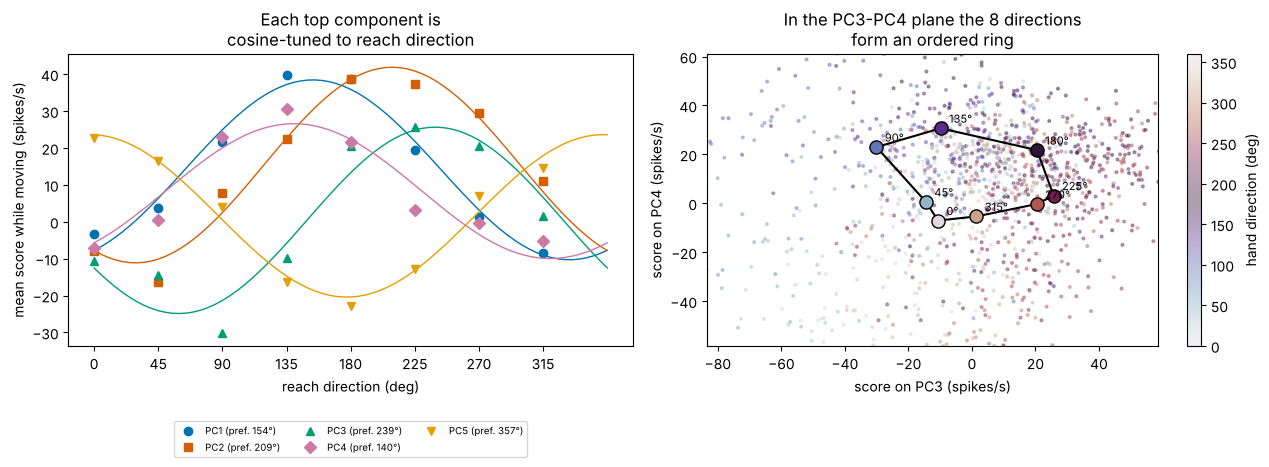

In [19]:
speed = np.linalg.norm(vel, axis=1)                                         # cm/s, shape (15536,)
direction = np.degrees(np.arctan2(vel[:, 1], vel[:, 0])) % 360              # deg, shape (15536,)
moving = speed > np.median(speed)
sector = ((direction + 22.5) // 45).astype(int) % 8                         # 0 = rightwards, 2 = upwards, ...
dirs = np.arange(8) * 45
dir_means = np.array([scores_m1[moving & (sector == d), :5].mean(axis=0) for d in range(8)])   # shape (8, 5), spikes/s
print("correlation of each score with hand speed:", np.round([np.corrcoef(scores_m1[:, j], speed)[0, 1] for j in range(5)], 2))

# Fit a cosine (Lesson 2) to each component's direction averages.
th = np.radians(dirs)
D_cos = np.column_stack([np.ones(8), np.cos(th), np.sin(th)])
fine = np.radians(np.arange(0, 361, 5))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for j in range(5):
    c = np.linalg.lstsq(D_cos, dir_means[:, j], rcond=None)[0]
    r2 = 1 - np.sum((dir_means[:, j] - D_cos @ c)**2) / np.sum((dir_means[:, j] - dir_means[:, j].mean())**2)
    pref = np.degrees(np.arctan2(c[2], c[1])) % 360
    print(f"PC{j + 1}: cosine fit R^2 = {r2:.2f}, preferred direction {pref:.0f} deg")
    axes[0].plot(dirs, dir_means[:, j], MARKERS[j], color=PALETTE[j], label=f'PC{j + 1} (pref. {pref:.0f}°)')
    axes[0].plot(np.degrees(fine), c[0] + c[1] * np.cos(fine) + c[2] * np.sin(fine), color=PALETTE[j], lw=1)
axes[0].set_xticks(dirs); axes[0].set_xlabel('reach direction (deg)'); axes[0].set_ylabel('mean score while moving (spikes/s)')
axes[0].set_title('Each top component is\ncosine-tuned to reach direction'); axes[0].legend(fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.24))

a_, b_ = 2, 3                                                               # PC3 and PC4: preferred directions about 100 deg apart
sub = np.flatnonzero(moving)[::6]
sc = axes[1].scatter(scores_m1[sub, a_], scores_m1[sub, b_], c=direction[sub], cmap='twilight', vmin=0, vmax=360, s=4, alpha=0.4)
plt.colorbar(sc, ax=axes[1], label='hand direction (deg)')
axes[1].plot(np.r_[dir_means[:, a_], dir_means[0, a_]], np.r_[dir_means[:, b_], dir_means[0, b_]], 'k-', lw=1.5)
for d in range(8):
    axes[1].scatter(dir_means[d, a_], dir_means[d, b_], s=90, color=plt.cm.twilight(dirs[d] / 360), edgecolor='black', zorder=3)
    axes[1].annotate(f'{dirs[d]}°', (dir_means[d, a_], dir_means[d, b_]), xytext=(6, 4), textcoords='offset points', fontsize=8)
lo, hi = np.percentile(scores_m1[sub][:, [a_, b_]], [2, 98], axis=0)
axes[1].set_xlim(lo[0], hi[0]); axes[1].set_ylim(lo[1], hi[1])
axes[1].set_xlabel('score on PC3 (spikes/s)'); axes[1].set_ylabel('score on PC4 (spikes/s)')
axes[1].set_title('In the PC3-PC4 plane the 8 directions\nform an ordered ring')
plt.tight_layout()
plt.show()

PCA was given only spike counts, yet each of its top five components behaves like the cosine-tuned neurons of Lesson 2: its average score follows a cosine of reach direction, each with a different preferred direction. Two components whose preferred directions are about 90° apart, like PC3 and PC4, together lay the eight directions out on an ordered ring. PC1 also rises with hand speed. The dominant patterns of this population are about the movement.

#### Interactive version: the ring in three dimensions, with PC1 as height

Rotate the view. The ring of direction averages sits in the PC3–PC4 plane, and PC1 adds a speed-related height.

In [20]:
fig_loop = go.Figure()
sub = np.flatnonzero(moving)[::8]
sub = sub[np.all(np.abs(scores_m1[sub][:, [0, 2, 3]]) < np.percentile(np.abs(scores_m1[moving][:, [0, 2, 3]]), 99, axis=0), axis=1)]   # drop extreme bins for a readable view
fig_loop.add_trace(go.Scatter3d(x=np.round(scores_m1[sub, 2], 1), y=np.round(scores_m1[sub, 3], 1), z=np.round(scores_m1[sub, 0], 1), mode='markers',
                                marker=dict(size=2, color=direction[sub], colorscale='Twilight', cmin=0, cmax=360, opacity=0.35,
                                            colorbar=dict(title='direction (deg)')), name='moving bins',
                                hovertemplate='PC3 %{x:.1f}<br>PC4 %{y:.1f}<br>PC1 %{z:.1f}<extra></extra>'))
loop = np.vstack([dir_means, dir_means[:1]])
fig_loop.add_trace(go.Scatter3d(x=loop[:, 2], y=loop[:, 3], z=loop[:, 0], mode='lines+markers+text', text=[f'{45 * d}°' for d in range(8)] + [''],
                                line=dict(color='black', width=5), marker=dict(size=6, color='black'), name='direction averages'))
fig_loop.update_layout(scene=dict(xaxis_title='PC3 (spikes/s)', yaxis_title='PC4 (spikes/s)', zaxis_title='PC1 (spikes/s)',
                                  xaxis=dict(showgrid=False), yaxis=dict(showgrid=False), zaxis=dict(showgrid=False)),
                       title='Motor cortex in PC3, PC4 and PC1 (the speed-related component), coloured by reach direction', template='plotly_white', width=850, height=620)
fig_loop.show(config=PLOTLY_CONFIG)

### How many components does a decoder need?

Lesson 5 decoded hand velocity from all neurons by least squares. Here we decode it from the top $k$ PCA scores instead (fitted on the training half, tested on the second half).

top   1 components: test R^2 = 0.026
top   2 components: test R^2 = 0.093
top   5 components: test R^2 = 0.457
top  10 components: test R^2 = 0.516
top  20 components: test R^2 = 0.565
top  50 components: test R^2 = 0.591
top 100 components: test R^2 = 0.633
top 170 components: test R^2 = 0.593


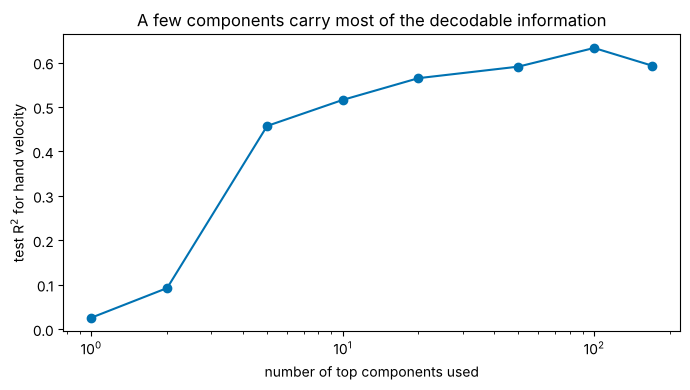

In [21]:
def decode_r2(F):
    # Test R^2 (mean of vx and vy) of a least-squares decoder from features F, shape (T, k).
    D = np.column_stack([np.ones(T_m1), F])
    B = np.linalg.lstsq(D[train], vel[train], rcond=None)[0]
    pred = D[~train] @ B
    return np.mean(1 - np.sum((vel[~train] - pred)**2, axis=0) / np.sum((vel[~train] - vel[~train].mean(axis=0))**2, axis=0))

k_dec = [1, 2, 5, 10, 20, 50, 100, Zm.shape[1]]
r2_dec = [decode_r2(scores_m1[:, :k]) for k in k_dec]
for k, r in zip(k_dec, r2_dec):
    print(f"top {k:>3} components: test R^2 = {r:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(k_dec, r2_dec, 'o-', color=PALETTE[0])
ax.set_xlabel('number of top components used'); ax.set_ylabel('test R$^2$ for hand velocity')
ax.set_title('A few components carry most of the decodable information')
plt.tight_layout()
plt.show()

**Interpretation.** Motor-cortex activity is not two-dimensional like our simulation: there is no sharp elbow, and about 36 of 170 components are needed for 80% of the training variance. Yet the top few components are clearly about the movement. Their direction averages form an ordered loop, PC1 tracks hand speed, and 10 components already support a velocity decoder with test $R^2 \approx 0.5$, against about 0.6 for all 170 neurons. Using 100 components does slightly better than all 170, because the dropped low-variance components are mostly noise that the decoder would otherwise overfit (Part 7's denoising, now on real data).

The test half shows how honest evaluation looks: 10 components capture 57% of the training variance but only 47% of the test variance, because the components were tuned to the training data.

**Limitations.** Raw PCA here is dominated by high-rate neurons (Part 5): the variance ranking is partly a ranking of firing rates. Smoothing with 100 ms concentrates variance in slow patterns. Movement and neural activity are confounded with time in the session. And "most variance" is still not "most behaviourally relevant": Exercise 7 tests how much better the top components are than random or bottom ones.

# **Part 10: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Covariance matrix | noise correlations between neurons; functional connectivity in fMRI | feature covariance; Gaussian models; whitening |
| PCA scores | neural population trajectories ("state space"); dimensionality of neural activity | low-dimensional embeddings; visualisation |
| Explained variance, scree | how many dimensions a population or brain network uses | choosing the dimension of a compressed representation |
| Low-rank reconstruction | denoising calcium-imaging movies and spike-sorting waveforms | compression; low-rank approximations (LoRA-style adapters) |
| Standardisation | z-scoring neurons or voxels before comparing them | feature scaling before PCA, regression and gradient descent (Lesson 15) |
| Leakage avoidance | fitting preprocessing on training trials only | `fit` on train, `transform` on test, inside a pipeline |
| Limitations | demixed PCA, dPCA, and LDA when conditions matter; nonlinear manifolds | supervised dimensionality reduction; autoencoders, UMAP |

Two classic uses deserve a name. **Spike sorting** projects each detected spike waveform onto its first few principal components; spikes from different neurons form separate clusters there. **Resting-state fMRI** analyses start from the covariance or correlation matrix between brain regions, and its eigenvectors are the dominant large-scale networks.

# **Part 11: Summary and Week 3 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Centring | $\mathbf{X}_c = \mathbf{X} - \bar{\mathbf{x}}$, `X - X.mean(axis=0)` | PCA studies variation, so centre first |
| Covariance | $\mathbf{C} = \mathbf{X}_c^{\mathsf T}\mathbf{X}_c/(n-1)$, `np.cov(X, rowvar=False)` | symmetric, positive semidefinite, units squared |
| Variance along $\mathbf{u}$ | $\mathbf{u}^{\mathsf T}\mathbf{C}\mathbf{u}$ | the Rayleigh quotient of Lesson 6 |
| Principal axes | eigenvectors of $\mathbf{C}$, eigenvalues sorted largest first | orthonormal; sign is arbitrary |
| Scores, loadings | $\mathbf{S} = \mathbf{X}_c\mathbf{Q}$; entries of $\mathbf{Q}$ | uncorrelated scores with variances $\lambda_k$ |
| Explained variance | $\lambda_k/\sum_j\lambda_j$; scree plot | eigenvalues sum to the total variance |
| Low-rank reconstruction | $\bar{\mathbf{x}} + \mathbf{X}_c\mathbf{Q}_k\mathbf{Q}_k^{\mathsf T}$ | best rank-$k$ fit; can denoise |
| Standardisation | z-scores; PCA of the correlation matrix | a choice: needed for mixed units |
| Leakage | fit mean, scale and components on training data | then apply unchanged to test data |
| Limitations | variance $\neq$ relevance; linear; equal eigenvalues; outliers | PCA is a baseline, not an answer |

**Week 2 ends here.** Weeks 1 and 2 built the linear-algebra toolkit: vectors, projections, matrices, least squares, eigenvalues and PCA. **Week 3** turns to calculus, starting with **Lesson 8 — Functions, limits and continuity**: the language for describing how a neuron's response changes with its input, which leads to derivatives, gradients and learning.